In [1]:
from google.colab import files

uploaded = files.upload()

Saving spam.zip to spam.zip


In [2]:
import zipfile
import os

with zipfile.ZipFile("spam.zip", "r") as zip_ref:
    zip_ref.extractall("spam_dataset")

print("ZIP extracted successfully!")

for root, dirs, filenames in os.walk("spam_dataset"):
    for filename in filenames:
        print(os.path.join(root, filename))

ZIP extracted successfully!
spam_dataset/spam_sms.csv


In [3]:
import pandas as pd
import glob
import os

csv_files = glob.glob("spam_dataset/**/*.csv", recursive=True)

if not csv_files:
    raise FileNotFoundError("No CSV file found inside spam.zip!")

csv_path = csv_files[0]

df = pd.read_csv(csv_path, encoding="latin-1")

print("Dataset loaded successfully!")
print("File:", os.path.basename(csv_path))
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
File: spam_sms.csv
Dataset shape: (5572, 2)
Columns: ['v1', 'v2']


,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [4]:
print("Missing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Missing values:
v1    0
v2    0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   v1      5572 non-null   object
 1   v2      5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB


SMS SPAM DETECTION USING LSTM

Original dataset shape: (5572, 2)
Dataset columns: ['v1', 'v2']

Message column: v2
Label column: v1

Missing values before cleaning:
message    0
label      0
dtype: int64

Dataset shape after cleaning: (5158, 2)

Class distribution:
label
Ham     4516
Spam     642
Name: count, dtype: int64

Number of selected messages: 2000

Training messages: 1280
Validation messages: 320
Testing messages: 400

Vocabulary size: 3887
Training sequence shape: (1280, 100)
Validation sequence shape: (320, 100)
Testing sequence shape: (400, 100)

MODEL ARCHITECTURE


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 100, 64)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 355,137 (1.35 MB)

 Trainable params: 355,137 (1.35 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 9s 92ms/step - accuracy: 0.8516 - loss: 0.5509 - val_accuracy: 0.8750 - val_loss: 0.3386
Epoch 2/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 0.9305 - loss: 0.1893 - val_accuracy: 0.9812 - val_loss: 0.0971
Epoch 3/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 54ms/step - accuracy: 0.9883 - loss: 0.0525 - val_accuracy: 0.9875 - val_loss: 0.0735
Epoch 4/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 39ms/step - accuracy: 0.9977 - loss: 0.0156 - val_accuracy: 0.9812 - val_loss: 0.0918
Epoch 5/10
40/40 ━━━━━━━━━━━━━━━━━━━━ 3s 38ms/step - accuracy: 1.0000 - loss: 0.0053 - val_accuracy: 0.9875 - val_loss: 0.0878

Model training completed!

FINAL TEST RESULTS
Accuracy  : 0.9925 (99.25%)
Precision : 0.9608
Recall    : 0.9800
F1-score  : 0.9703

Classification Report:
              precision    recall  f1-score   support

         Ham       1.00      0.99      1.00       350
        Spam       0.96      0.98      0.97        50

    accuracy                           0.99  

,Accuracy,Precision,Recall,F1-score
0,0.9925,0.960784,0.98,0.970297


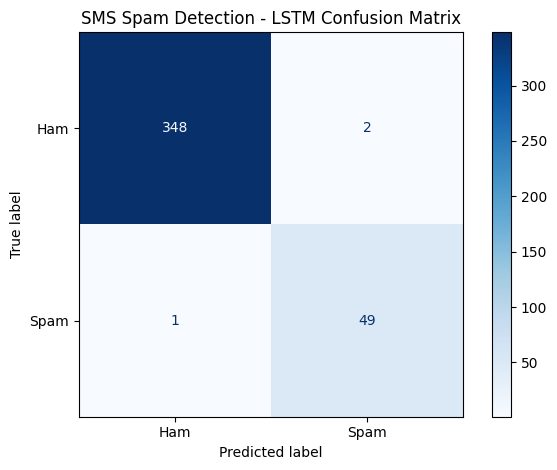

Confusion matrix values:
[[348   2]
 [  1  49]]


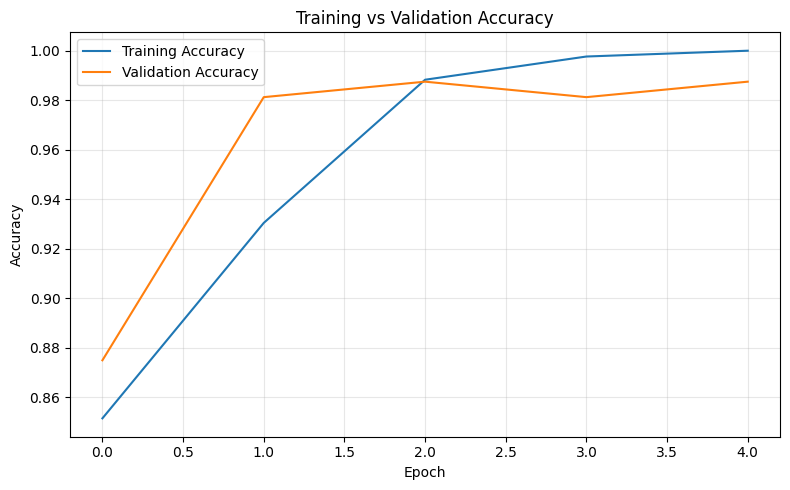

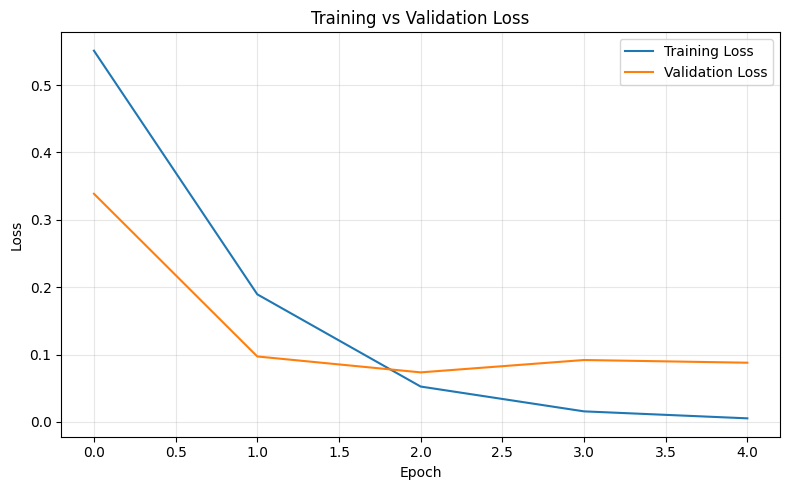


UNSEEN SMS PREDICTIONS

Message: Congratulations! You won a free prize. Claim your reward now!
Prediction: SPAM
Spam probability: 94.34%

Message: Hey, are we meeting at college tomorrow?
Prediction: HAM
Spam probability: 0.09%

Message: URGENT! You have won a cash reward. Call now to claim.
Prediction: SPAM
Spam probability: 96.01%

Message: Please send me the class notes when you are free.
Prediction: HAM
Spam probability: 0.20%

PROJECT COMPLETED SUCCESSFULLY!
Saved files are in the sms_spam_outputs folder.



<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
# ============================================================
# SMS SPAM DETECTION USING DEEP LEARNING (LSTM)
# Google Colab - Complete Project
# ============================================================

import os
import re
import json
import pickle
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from IPython.display import display

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

SEED = 42
MAX_WORDS = 5000
MAX_LEN = 100
EPOCHS = 10
BATCH_SIZE = 32

np.random.seed(SEED)
random.seed(SEED)
tf.random.set_seed(SEED)

os.makedirs("sms_spam_outputs", exist_ok=True)

print("=" * 60)
print("SMS SPAM DETECTION USING LSTM")
print("=" * 60)

# ------------------------------------------------------------
# 2. CHECK AND PREPARE DATASET
# Uses df already loaded from your ZIP file
# ------------------------------------------------------------

if "df" not in globals():
    raise ValueError(
        "Dataset not found. Run your CSV loading cell first."
    )

data = df.copy()

# Remove unnecessary unnamed columns
data = data.loc[
    :, ~data.columns.astype(str).str.startswith("Unnamed")
]

print("\nOriginal dataset shape:", data.shape)
print("Dataset columns:", data.columns.tolist())

# Automatically identify the text and label columns
def find_column(columns, candidates):
    for candidate in candidates:
        for col in columns:
            if str(col).strip().lower() == candidate:
                return col
    return None

text_col = find_column(
    data.columns,
    ["message", "text", "sms", "v2", "message_body", "content"]
)

label_col = find_column(
    data.columns,
    ["label", "category", "class", "v1", "target", "type"]
)

# Fallback: detect common spam/ham label values
if label_col is None:
    for col in data.columns:
        values = set(
            data[col].dropna().astype(str).str.strip().str.lower().unique()
        )
        if values.intersection({"spam", "ham", "not spam", "legitimate"}):
            label_col = col
            break

# Fallback: choose the longest text-like column
if text_col is None and label_col is not None:
    candidates = [
        col for col in data.columns
        if col != label_col
        and (
            pd.api.types.is_object_dtype(data[col])
            or pd.api.types.is_string_dtype(data[col])
        )
    ]

    if candidates:
        text_col = max(
            candidates,
            key=lambda col: data[col].fillna("").astype(str).str.len().mean()
        )

if text_col is None or label_col is None:
    raise ValueError(
        "Could not identify text and label columns. "
        "Inspect the printed column names and set them manually."
    )

data = data[[text_col, label_col]].copy()
data.columns = ["message", "label"]

print("\nMessage column:", text_col)
print("Label column:", label_col)

# ------------------------------------------------------------
# 3. HANDLE MISSING VALUES AND DUPLICATES
# ------------------------------------------------------------

print("\nMissing values before cleaning:")
print(data.isnull().sum())

data = data.dropna(subset=["message", "label"]).copy()

data["message"] = data["message"].astype(str).str.strip()
data["label"] = data["label"].astype(str).str.strip().str.lower()

data = data[data["message"] != ""]
data = data.drop_duplicates(subset=["message"]).reset_index(drop=True)

# Convert labels into binary values: spam=1, ham=0
label_map = {
    "spam": 1,
    "ham": 0,
    "not spam": 0,
    "legitimate": 0,
    "normal": 0,
    "1": 1,
    "0": 0
}

data["label"] = data["label"].map(label_map)
data = data.dropna(subset=["label"]).copy()
data["label"] = data["label"].astype(int)

if data["label"].nunique() != 2:
    raise ValueError(
        "Both spam and ham classes are required. "
        "Check your original dataset labels."
    )

print("\nDataset shape after cleaning:", data.shape)
print("\nClass distribution:")
print(data["label"].value_counts().rename(index={0: "Ham", 1: "Spam"}))

# ------------------------------------------------------------
# 4. SELECT APPROXIMATELY 2,000 LABELLED MESSAGES
# ------------------------------------------------------------

sample_size = min(2000, len(data))

if sample_size < len(data):
    data, _ = train_test_split(
        data,
        train_size=sample_size,
        random_state=SEED,
        stratify=data["label"]
    )

data = data.reset_index(drop=True)

print("\nNumber of selected messages:", len(data))

# ------------------------------------------------------------
# 5. TEXT PREPROCESSING
# ------------------------------------------------------------

def clean_text(text):
    text = text.lower()
    text = re.sub(r"http\S+|www\.\S+", " URL ", text)
    text = re.sub(r"\S+@\S+", " EMAIL ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

X = data["message"].apply(clean_text).values
y = data["label"].values

# Split into training, validation and testing datasets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)

X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.20,
    random_state=SEED,
    stratify=y_train
)

print("\nTraining messages:", len(X_train))
print("Validation messages:", len(X_val))
print("Testing messages:", len(X_test))

# ------------------------------------------------------------
# 6. TOKENIZATION AND PADDING
# ------------------------------------------------------------

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>"
)

# Fit only on training text to avoid data leakage
tokenizer.fit_on_texts(X_train)

def prepare_sequences(messages):
    sequences = tokenizer.texts_to_sequences(messages)
    return pad_sequences(
        sequences,
        maxlen=MAX_LEN,
        padding="post",
        truncating="post"
    )

X_train_pad = prepare_sequences(X_train)
X_val_pad = prepare_sequences(X_val)
X_test_pad = prepare_sequences(X_test)

vocab_size = min(
    MAX_WORDS,
    len(tokenizer.word_index) + 1
)

print("\nVocabulary size:", vocab_size)
print("Training sequence shape:", X_train_pad.shape)
print("Validation sequence shape:", X_val_pad.shape)
print("Testing sequence shape:", X_test_pad.shape)

# ------------------------------------------------------------
# 7. BUILD THE LSTM MODEL
# ------------------------------------------------------------

model = Sequential([
    tf.keras.Input(shape=(MAX_LEN,)),
    Embedding(
        input_dim=MAX_WORDS,
        output_dim=64,
        mask_zero=True
    ),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation="relu"),
    Dropout(0.2),
    Dense(1, activation="sigmoid")
])

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("\nMODEL ARCHITECTURE")
model.summary()

# ------------------------------------------------------------
# 8. TRAIN THE MODEL
# ------------------------------------------------------------

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

history = model.fit(
    X_train_pad,
    y_train,
    validation_data=(X_val_pad, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping],
    verbose=1
)

print("\nModel training completed!")

# ------------------------------------------------------------
# 9. EVALUATE THE MODEL
# ------------------------------------------------------------

y_prob = model.predict(X_test_pad, verbose=0).ravel()
y_pred = (y_prob >= 0.5).astype(int)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("\n" + "=" * 45)
print("FINAL TEST RESULTS")
print("=" * 45)

print(f"Accuracy  : {accuracy:.4f} ({accuracy * 100:.2f}%)")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1-score  : {f1:.4f}")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=[0, 1],
    target_names=["Ham", "Spam"],
    zero_division=0
))

metrics_df = pd.DataFrame([{
    "Accuracy": accuracy,
    "Precision": precision,
    "Recall": recall,
    "F1-score": f1
}])

display(metrics_df)

metrics_df.to_csv(
    "sms_spam_outputs/evaluation_metrics.csv",
    index=False
)

# ------------------------------------------------------------
# 10. DISPLAY AND SAVE CONFUSION MATRIX
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ham", "Spam"]
)

disp.plot(cmap="Blues", values_format="d")
plt.title("SMS Spam Detection - LSTM Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "sms_spam_outputs/confusion_matrix.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

print("Confusion matrix values:")
print(cm)

# ------------------------------------------------------------
# 11. PLOT TRAINING PERFORMANCE
# ------------------------------------------------------------

plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation Accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "sms_spam_outputs/accuracy_graph.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "sms_spam_outputs/loss_graph.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()

# ------------------------------------------------------------
# 12. PREDICT UNSEEN SMS MESSAGES
# ------------------------------------------------------------

def predict_sms(message):
    cleaned = clean_text(message)
    padded = prepare_sequences([cleaned])

    probability = float(model.predict(padded, verbose=0)[0][0])
    prediction = "SPAM" if probability >= 0.5 else "HAM"

    print("\nMessage:", message)
    print("Prediction:", prediction)
    print(f"Spam probability: {probability:.2%}")

    return prediction

print("\n" + "=" * 45)
print("UNSEEN SMS PREDICTIONS")
print("=" * 45)

test_messages = [
    "Congratulations! You won a free prize. Claim your reward now!",
    "Hey, are we meeting at college tomorrow?",
    "URGENT! You have won a cash reward. Call now to claim.",
    "Please send me the class notes when you are free."
]

for message in test_messages:
    predict_sms(message)

# ------------------------------------------------------------
# 13. SAVE MODEL AND TOKENIZER
# ------------------------------------------------------------

model.save("sms_spam_outputs/spam_lstm.keras")

with open("sms_spam_outputs/tokenizer.pkl", "wb") as file:
    pickle.dump(tokenizer, file)

with open("sms_spam_outputs/config.json", "w") as file:
    json.dump({
        "model": "LSTM",
        "max_words": MAX_WORDS,
        "max_len": MAX_LEN,
        "threshold": 0.5,
        "label_mapping": {"ham": 0, "spam": 1}
    }, file, indent=4)

print("\n" + "=" * 60)
print("PROJECT COMPLETED SUCCESSFULLY!")
print("Saved files are in the sms_spam_outputs folder.")
print("=" * 60)

# ------------------------------------------------------------
# 14. DOWNLOAD ALL OUTPUTS AS A ZIP
# ------------------------------------------------------------

import shutil
from google.colab import files

shutil.make_archive(
    "sms_spam_outputs",
    "zip",
    "sms_spam_outputs"
)

print("\nDownloading trained model, tokenizer, metrics and graphs...")
files.download("sms_spam_outputs.zip")